# Cell annotation

## Imports

In [ ]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
import warnings
warnings.filterwarnings("ignore")  # umap deprecation warnings related to numba do not concern us.

import itertools as it

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc


In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))
from pipeline_config import load_config

cfg = load_config()  # dataset wybierasz w pipeline_config.toml (`active`) albo env BOOLAI_DATASET
print(cfg.describe())
assert cfg.preliminary_annotation, (
    f"dataset {cfg.dataset!r} ma preliminary_annotation=false — ten krok jest pomijany"
)

In [4]:
# Source - https://stackoverflow.com/a/52858398
# Posted by user4234032, modified by community. See post 'Timeline' for change history
# Retrieved 2026-04-22, License - CC BY-SA 4.0

import os
notebook_path = os.path.abspath("1. Clusterization.ipynb")

In [5]:
#from celltypist import models
from scipy.sparse import csr_matrix

In [6]:
%ls *csv

counts_hvgs.csv*   merged_dataset.csv*                   sc_metadata.csv*
dataset_hvgs.csv*  scboolseq_inferred_observations.csv*


In [7]:
import anndata as ad

In [8]:
#import scarches as sca

In [10]:
import scvi

### Helper functions and constants

Here we define dictionary that maps Cell Ontology types into *Herault 2023* defined HSC subtypes.

In [12]:
cell_type_mapping = {
    # --- Komórki Macierzyste i Progenitorowe ---
    'hematopoietic stem cell': 'iHSC',
    'hematopoietic precursor cell': 'preDiff',
    'megakaryocyte-erythroid progenitor cell': 'pMk',
    'granulocyte monocyte progenitor cell': 'preDiff',
    
    # --- Ukierunkowanie Limfoidalne (pLymph) ---
    'lymphoid lineage restricted progenitor cell': 'pLymph',
    'early pro-B cell': 'pLymph',
    'late pro-B cell': 'pLymph',
    'precursor B cell': 'pLymph',
    'immature B cell': 'pLymph',
    'naive B cell': 'pLymph',
    'B cell': 'pLymph',
    'plasma cell': 'pLymph',
    'naive T cell': 'pLymph',
    'CD4-positive, alpha-beta T cell': 'pLymph',
    'CD8-positive, alpha-beta T cell': 'pLymph',
    'mature alpha-beta T cell': 'pLymph',
    'natural killer cell': 'pLymph',
    'innate lymphoid cell': 'pLymph',
    
    # --- Ukierunkowanie Erytroidalne (pEr) ---
    'erythroid progenitor cell, mammalian': 'pEr',
    'proerythroblast': 'pEr',
    'erythroblast': 'pEr',
    
    # --- Ukierunkowanie Mieloidalne (pNeuMast) ---
    'granulocytopoietic cell': 'pNeuMast',
    'granulocyte': 'pNeuMast',
    'neutrophil': 'pNeuMast',
    'eosinophil': 'pNeuMast',
    'basophil': 'pNeuMast',
    'mast cell': 'pNeuMast',
    'promonocyte': 'pNeuMast',
    'monocyte': 'pNeuMast',
    'macrophage': 'pNeuMast',
    'conventional dendritic cell': 'pNeuMast',
    'plasmacytoid dendritic cell': 'pNeuMast',
    
    # --- Komórki Nienależące do linii HSPC (Nie dotyczy) ---
    'stromal cell': None,
    'endothelial cell': None
}

### Overview of the pipeline:

> The binarization-based annotation flow (a) — HVG import, scBoolSeq training, marker binarization, and Leiden majority-vote label propagation — has been moved to `3. Final Cell Annotation.ipynb` as the canonical end-to-end pipeline. This notebook keeps the exploratory/alternative annotation methods.

1. Manual annotation methods  
   a) Binarization based — see `3. Final Cell Annotation.ipynb`  
   b) Clusterization based (**from markers to clusters**)  
   c) Clusterization based (**from clusters to markers**)
2. Automatic annotation methods  
   a) Based on pre-defined classifier (**CellTypist**)  
   b) Based on self-trained classifier (**Cyclone**)  
   c) Based on self-trained **VAE** and embeddings similarity (**scArches**)


# Manual Annotation

Reload the HVG matrix and marker definitions here, since the cells that originally produced them now live in `3. Final Cell Annotation.ipynb`. Needed by the marker-based clustering sections below.


In [ ]:
data = pd.read_csv(cfg.path("hvgs_csv"), index_col=0)

from markers import (
    positive_markers,
    states_and_markers,
)
marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
marker_genes = marker_genes[marker_genes.isin(data.columns)]


### Markers based annotation (markers -> clusters -> annotation)

Here we check the method of annotation purely on markers knowledge and found clusters.  
In the end we perform Gene Differentiation Analysis and present markers distribution in identified clusters.

In [ ]:
adata_herault = sc.AnnData(data, dtype=np.float64)

In [ ]:
marker_genes_in_data = {}
for ct, markers in states_and_markers.items():
    markers_found = []
    for marker in markers:
        if marker in adata_herault.var.index:
            markers_found.append(marker)
    marker_genes_in_data[ct] = markers_found

In [ ]:
adata_herault.layers["counts"] = adata.X

In [ ]:
adata.X = adata.layers["scran_normalization"]

In [ ]:
sc.tl.pca(adata_herault, n_comps=50, use_highly_variable=False)

In [ ]:
sc.pp.neighbors(adata_herault)

In [ ]:
sc.tl.umap(adata_herault)

In [ ]:
hematopoesis_cts = [
    ct for ct, markers in states_and_markers.items()
]

In [ ]:
hematopoesis_cts

In [ ]:
for ct in hematopoesis_cts:
    print(f"{ct.upper()}:")  # print cell subtype name
    sc.pl.umap(
        adata_herault,
        color=marker_genes_in_data[ct],
        vmin=0,
        vmax="p99",  # set vmax to the 99th percentile of the gene count instead of the maximum, to prevent outliers from making expression in other cells invisible. Note that this can cause problems for extremely lowly expressed genes.
        sort_order=False,  # do not plot highest expression on top, to not get a biased view of the mean expression among cells
        frameon=False,
        cmap="Reds",  # or choose another color map e.g. from here: https://matplotlib.org/stable/tutorials/colors/colormaps.html
    )
    print("\n\n\n")  # print white space for legibility

Here one can see how our dataset gene expression profiles are populated with specific marker expressions on the UMAP plot.

In [ ]:
sc.tl.leiden(adata_herault, resolution=1, key_added="leiden_1")

In [ ]:
hematopoesis_markers = {
    ct: [m for m in ct_markers if m in adata_herault.var.index]
    for ct, ct_markers in states_and_markers.items()
    if ct in hematopoesis_cts
}

In [ ]:
sc.pl.dotplot(
    adata_herault,
    groupby="leiden_1",
    var_names=hematopoesis_markers,
    standard_scale="var",  # standard scale: normalize each gene to range from 0 to 1
)

This dotplot shows how *apriori* input markers are distributed alongside obtained clusters and how they differentiate them in order to 

### Clusterization based annotation (clusters -> markers -> annotation)

This approach reverse the order of previous method by first identifying clusters based on GEPs distances and then analyzing,
which genes are distinctively expressed in them.  
Connecting these *markers* with known cell types, allows whole-cluster annotations.

In [ ]:
first_plot

In [ ]:
sc.tl.rank_genes_groups(
    adata, groupby="leiden_res1", method="wilcoxon", key_added="dea_leiden_1"
)

In [ ]:
sc.tl.dendrogram(
    adata,
    groupby="leiden_res1",
)

sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res1", standard_scale="var", n_genes=5, key="dea_leiden_1"
)

In [ ]:
sc.tl.filter_rank_genes_groups(
    adata,
    min_in_group_fraction=0.2,
    max_out_group_fraction=0.2,
    key="dea_leiden_1",
    key_added="dea_leiden_1_filtered",
)

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden_res1",
    standard_scale="var",
    n_genes=5,
    key="dea_leiden_1_filtered",
)

This dotplot shows, which genes differentiate obtained clusters the most.

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata,
    groupby="leiden_res1",
    standard_scale="var",
    var_names=hematopoesis_markers,
    key="dea_leiden_1_filtered",
)

Here we analyze what are the differences between *marker genes* expression levels of specific cell types between found clusters.

In [ ]:
cl_annotation = {
    "8": "pEr", #gata, klf
    #"6": "Transitional B",
}

In [ ]:
hematopoesis_markers

In [ ]:
adata

In [ ]:
adata.uns['dea_leiden_1_filtered']

### Only subset marker genes based annotation

Here we explore what happens if we analyze our data limiting only to *apriori* known marker genes.

In [ ]:
adata = sc.AnnData(data.loc[:, marker_genes], dtype=np.float64)

In [ ]:
sc.pp.neighbors(adata)

In [ ]:
sc.tl.umap(adata)

In [ ]:
sc.tl.leiden(
    adata, key_added="leiden_res1", resolution=1.0, flavor="igraph", n_iterations=2
)

In [ ]:
sc.tl.rank_genes_groups(
    adata, groupby="leiden_res1", method="wilcoxon", key_added="dea_leiden_1"
)

In [ ]:
sc.tl.dendrogram(
    adata,
    groupby="leiden_res1",
)

plot = sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden_res1", standard_scale="var", n_genes=5, key="dea_leiden_1", return_fig=True
)

In [ ]:
plot

In [ ]:
plot.savefig("dotplot5.pdf")

Here we plot gene differeces in form of dotplot to check, which known marker genes differentiate clusters obtained with GAPs distances of profiles limited only to *marker genes*.

## Non-euclidean distance based annotation

Here we want to explore the usage of different method of identyfing clusters and, therefore assigning cells to them.  
Previous appproaches used euclidean distance to find neighbors for specific profiles.  
We want to challenge this with different distance metric.

# Automated annotation

Following methods get rid of huge human contribution of visual analysis/manual inspection.  
Instead they are based solely on automatization based on building ML models that incorporate known markers/utilize all genes from dataset to differentiate cell types.

## Based on pre-trained classifier - CellTypist

First method utilize simple logistic regression classifier based on models pre-trained on some marker geners subsets.

In [ ]:
adata = sc.AnnData(data, dtype=np.float64)


In [ ]:
adata.layers["counts"] = adata.X

In [ ]:
adata_celltypist = adata.copy()  # make a copy of our adata
adata_celltypist.X = adata.layers["counts"]  # set adata.X to raw counts
sc.pp.normalize_total(
    adata_celltypist, target_sum=10**4
)  # normalize to 10,000 counts per cell
sc.pp.log1p(adata_celltypist)  # log-transform
# make .X dense instead of sparse, for compatibility with celltypist:
#adata_celltypist.X = adata_celltypist.X.toarray()

In [ ]:
model_ultima = models.Model.load(model="Adult_cHSPCs_Ultima.pkl")
model_illumina = models.Model.load(model="Adult_cHSPCs_Illumina.pkl")

In [ ]:
model_ultima.cell_types

## Based on self-trained classifier - Cyclone

Second method is based on paper that reference will be added here soon.

## Based on variational autoencoder arch and embeddings similarity - scArches


Cells are annotated by mapping our query dataset into the latent space of an scVI reference model trained on labelled bone marrow data (CELLxGENE census), then transferring labels from the nearest reference cells in that space. Two ways of getting the reference model are compared below (A: pretrained, B: self-trained) — both go through the same `cell_annotation.reference_mapping` functions (gene alignment -> query mapping -> latent embedding -> label transfer), ported out of the ~280 duplicated cells this section used to be (see git history of `1. Cell Annotation.ipynb` for the FACS-reference variant, abandoned there as "DALEJ NIE IDZIEMY").


In [ ]:
import cellxgene_census
import scvi

from cell_annotation.reference_mapping import (
    map_var_names_to_census_ids,
    load_pretrained_reference_model,
    align_query_to_model,
    train_reference_model,
    map_query_to_reference,
    get_latent_adata,
    plot_training_history,
    combine_reference_query,
    transfer_labels,
)


In [ ]:
census_version = "2025-11-08"
organism = "mus_musculus"


### Reference & query data


We download a labelled bone marrow reference from CELLxGENE census, and load our own HVG counts as the query. Census indexes genes by Ensembl id, so the query is remapped from gene symbols before either branch below.


In [ ]:
%%time
with cellxgene_census.open_soma(census_version=census_version) as census:
    marrow_reference = cellxgene_census.get_anndata(
        census=census,
        measurement_name="RNA",
        organism="Mus musculus",
        obs_value_filter="tissue == 'bone marrow'",
    )
marrow_reference.obs["cell_type"].value_counts()


In [ ]:
data = pd.read_csv(cfg.path("counts_hvgs_csv"), index_col=0)
query_adata = sc.AnnData(data, dtype=np.float64)
query_census = map_var_names_to_census_ids(
    query_adata, census_version=census_version, organism=organism
)
print(f"{query_census.n_vars}/{query_adata.n_vars} query genes mapped to a census id")


### A) Pretrained scVI model (CELLxGENE census)


Downloads the ready-trained mouse scVI model census ships, and only fine-tunes a query-mapping ("surgery") model on top of its frozen weights — no reference training required. The labelled `marrow_reference` subset is mapped through the same frozen model too, purely to have a labelled anchor for label transfer/visualisation.


In [ ]:
model_dir = f"{census_version}-scvi-{organism}"
model_filename = f"{model_dir}/scvi.model"
!aws s3 cp --no-sign-request --no-progress --only-show-errors s3://cellxgene-contrib-public/models/scvi/{census_version}/{organism}/model.pt {model_filename}/


In [ ]:
pretrained_reference_model = load_pretrained_reference_model(model_filename)


In [ ]:
marrow_aligned = align_query_to_model(marrow_reference, pretrained_reference_model)
query_aligned = align_query_to_model(query_census, pretrained_reference_model)


In [ ]:
%%time
marrow_model_pretrained = map_query_to_reference(
    marrow_aligned, pretrained_reference_model, max_epochs=100,
)
query_model_pretrained = map_query_to_reference(
    query_aligned, pretrained_reference_model,
    save_path="surgery_model_marrow_pretrained",
)


In [ ]:
plot_training_history(marrow_model_pretrained)
plot_training_history(query_model_pretrained)


In [ ]:
marrow_latent_pretrained = get_latent_adata(
    marrow_model_pretrained, marrow_aligned, role="reference", cell_type_key="cell_type",
)
query_latent_pretrained = get_latent_adata(query_model_pretrained, query_aligned, role="query")
combined_pretrained = combine_reference_query(marrow_latent_pretrained, query_latent_pretrained)


In [ ]:
predicted_labels_pretrained = transfer_labels(marrow_latent_pretrained, query_latent_pretrained)
combined_pretrained.obs.loc[predicted_labels_pretrained.index, "cell_type"] = (
    predicted_labels_pretrained.values
)
predicted_labels_pretrained.value_counts()


In [ ]:
sc.pl.umap(
    combined_pretrained,
    color=["reference_or_query", "cell_type"],
    frameon=False,
    wspace=0.6,
)


### B) Self-trained reference (CELLxGENE bone marrow census counts)


Same recipe, but the reference model is trained from scratch on the raw `marrow_reference` counts restricted to genes shared with our query, instead of reusing census's pretrained model.


In [ ]:
common_genes = marrow_reference.var_names.intersection(query_census.var_names)
marrow_common = marrow_reference[:, common_genes].copy()
query_common = query_census[:, common_genes].copy()
print(f"{len(common_genes)} genes shared between reference and query")


In [ ]:
%%time
own_reference_model = train_reference_model(marrow_common, save_path="ref_marrow")


In [ ]:
%%time
query_model_own = map_query_to_reference(
    query_common, own_reference_model, save_path="surgery_model_marrow_own",
)


In [ ]:
plot_training_history(own_reference_model)
plot_training_history(query_model_own)


In [ ]:
marrow_latent_own = get_latent_adata(
    own_reference_model, marrow_common, role="reference", cell_type_key="cell_type",
)
query_latent_own = get_latent_adata(query_model_own, query_common, role="query")
combined_own = combine_reference_query(marrow_latent_own, query_latent_own)


In [ ]:
predicted_labels_own = transfer_labels(marrow_latent_own, query_latent_own)
combined_own.obs.loc[predicted_labels_own.index, "cell_type"] = predicted_labels_own.values
predicted_labels_own.value_counts()


### Eksport wstępnych etykiet dla `2. Data Integration.ipynb`

To jest etap 1 dwuetapowego etykietowania: automatyczny transfer learning (scVI/scArches) daje **wstępny** `label`/`discard`, na którym `2. Data Integration.ipynb` robi integrację batchy i regresję cyklu komórkowego; dopiero `3. Final Cell Annotation.ipynb` liczy **finalne** etykiety (scBoolSeq + Leiden + głosowanie) na już skorygowanych danych i nadpisuje `cell_annotation_metadata.tsv` tą ostateczną wersją. Te dwa etapy nie mogą dzielić tej samej nazwy pliku (inaczej powstaje cykl 2↔3) — stąd osobny plik `preliminary_cell_annotation_metadata.tsv`.

Chwilowo oba warianty (A: pretrained, B: self-trained) zostają w notebooku jako opcje do porównania, ale do eksportu używamy **wariantu B (self-trained)** — działa lepiej niż pretrained na tym datasecie.

`predicted_labels_own` to etykiety Cell Ontology (z `marrow_reference.obs['cell_type']`, transfer przez KNN w przestrzeni latentnej) — mapujemy je przez `cell_type_mapping` (zdefiniowany na początku notebooka) na podtypy HSC w nazewnictwie Hérault. Terminy jawnie zmapowane na `None` (`stromal cell`, `endothelial cell` — kontaminacja spoza linii HSPC) dostają `discard=True`; terminy, których `cell_type_mapping` w ogóle nie zna, dostają `label="Unknown"` ale **nie** są odrzucane (nie chcemy tracić komórek tylko dlatego, że słownik mapowania jest niekompletny).

In [ ]:
mapped_label = predicted_labels_own.map(cell_type_mapping)
non_hspc_terms = [term for term, mapped in cell_type_mapping.items() if mapped is None]
is_non_hspc = predicted_labels_own.isin(non_hspc_terms)

preliminary_metadata = pd.DataFrame(
    {
        "label": mapped_label.fillna("Unknown"),
        "discard": is_non_hspc,
    },
    index=predicted_labels_own.index,
)
print(preliminary_metadata["label"].value_counts(dropna=False))
print(f"discard=True (kontaminacja stromal/endothelial): {preliminary_metadata['discard'].sum()} / {len(preliminary_metadata)}")

preliminary_metadata.to_csv(cfg.path("preliminary_annotation_tsv"), sep="\t")

In [ ]:
sc.pl.umap(
    combined_own,
    color=["reference_or_query", "cell_type"],
    frameon=False,
    wspace=0.6,
)


## Probabilistic annotation based on marker matrix

In [28]:
from scvi.external import CellAssign

In [29]:
from markers import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

In [30]:
states_and_markers

{'iHSC': {'Bclaf1', 'Fli1', 'Foxp1', 'Kdm5b', 'Srf'},
 'srHSC': {'Bclaf1', 'Srf'},
 'ifnHSC': {'Irf1', 'Irf7', 'Irf9', 'Stat1'},
 'qHSC': {'Egr1', 'Fli1', 'Gata2', 'Junb', 'Tal1'},
 'preDiff': {'Hoxa9', 'Myc', 'Sox4', 'Spi1'},
 'pLymph': {'Ikzf1', 'Zbtb16'},
 'pNeuMast': {'Cebpa', 'Spi1'},
 'pEr': {'Gata1', 'Klf1', 'Zfpm1'},
 'pMk': {'Fli1', 'Gata1', 'Zfpm1'}}

In [31]:
prior_markers = {
    obs: positive_markers(markers)
    for obs, markers
    in states_and_markers.items()
}

In [ ]:
adata_herault = ad.read_h5ad(cfg.path("merged_h5ad"))

In [33]:
for state in prior_markers:
    prior_markers[state] = {marker: 1 for marker in prior_markers[state] if marker in adata_herault.var_names}

In [34]:
df = pd.DataFrame(prior_markers).fillna(0)
#df['other'] = 0

In [35]:
lib_size = adata_herault.X.sum(1)
adata_herault.obs["size_factor"] = lib_size / np.mean(lib_size)

In [36]:
bdata_herault = adata_herault[:, df.index].copy()

In [37]:
scvi.external.CellAssign.setup_anndata(bdata_herault, size_factor_key="size_factor")

In [38]:
prob_model = CellAssign(bdata_herault, df)

In [39]:
prob_model.train()

GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Training:   0%|          | 0/400 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=400` reached.


<Axes: xlabel='epoch'>

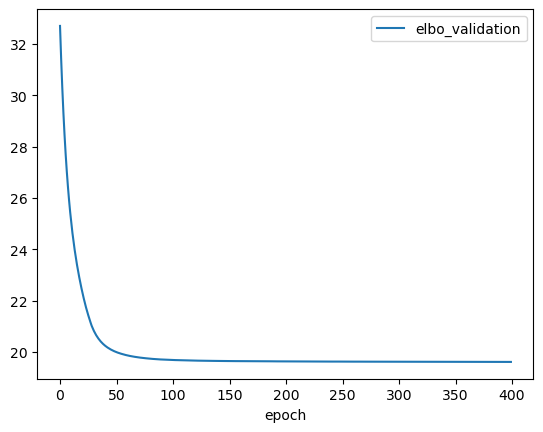

In [40]:
prob_model.history["elbo_validation"].plot()

In [41]:
predictions = prob_model.predict()

In [42]:
predictions.head()

,iHSC,srHSC,ifnHSC,qHSC,preDiff,pLymph,pNeuMast,pEr,pMk
0,5.325119e-09,1.098357e-07,2.446904e-05,0.997848,1.111098e-06,1.225239e-06,1.886386e-05,0.002097,8.640823e-06
1,8.838678e-13,2.575387e-10,9.721527e-09,0.999996,2.638605e-09,6.859385e-10,1.061957e-08,0.000004,1.004652e-07
2,5.108132e-13,7.245833e-08,1.854709e-05,0.998015,8.661712e-08,4.221245e-06,1.317878e-07,0.001959,2.267629e-06
3,5.773655e-19,4.886191e-10,1.076993e-07,0.996765,2.100917e-08,5.620475e-10,3.213279e-03,0.000023,2.974011e-09
4,1.380796e-19,9.674631e-10,9.043629e-08,0.999992,6.031089e-09,5.860109e-10,5.081518e-08,0.000007,1.908105e-07


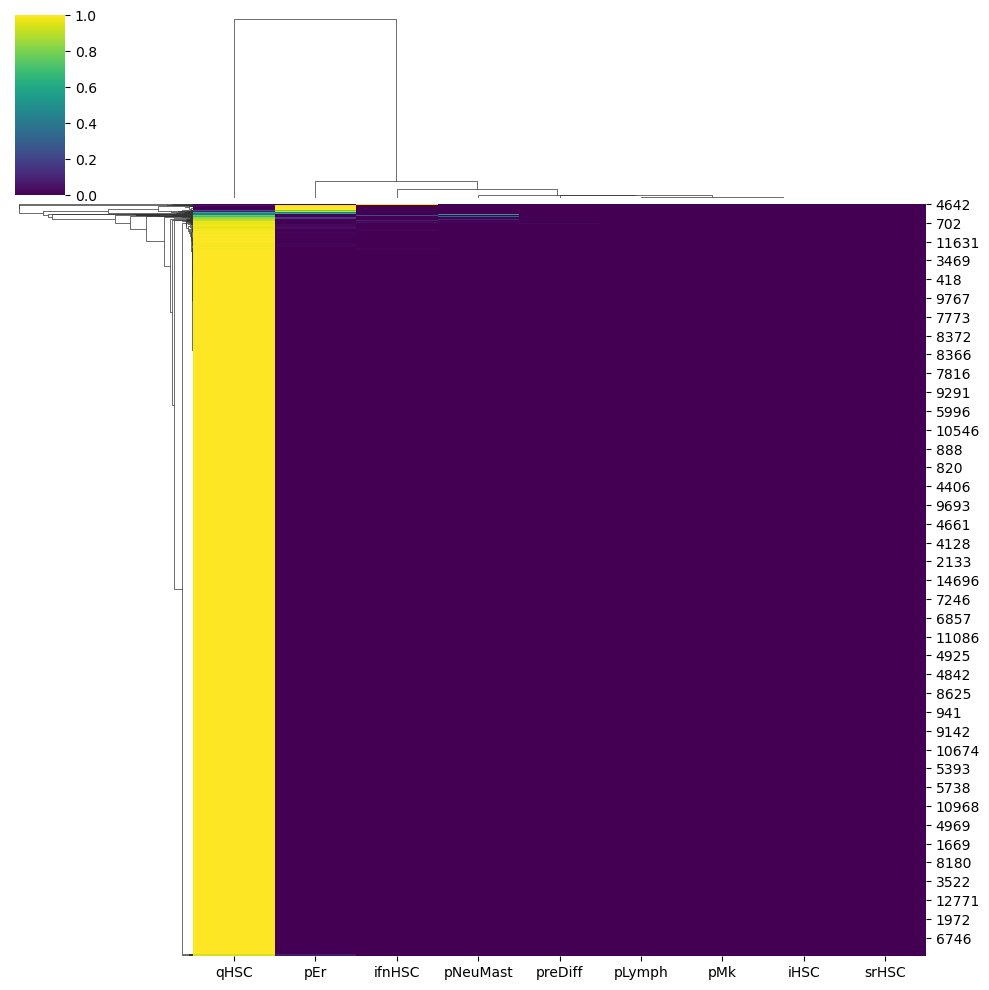

In [43]:
sns.clustermap(predictions, cmap="viridis")